Original IQ samples: 20480000
Original sample rate: 2048000 samples/sec
Recording duration: 10.0 seconds


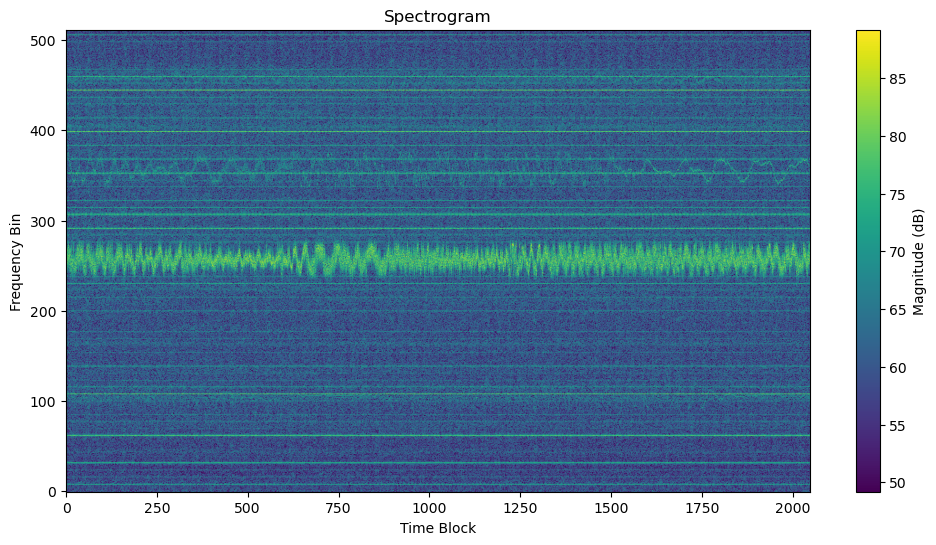

In [7]:
import numpy as np 
from pathlib import Path 
from load_file import load_file

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\wfm_wqnr_10sec.bin")

samples = load_file(file_path)

# Original sample rate 
fs = 2_048_000  # sampling freq 

print("Original IQ samples:", len(samples))
print("Original sample rate:", fs, "samples/sec") 
print("Recording duration:", len(samples) / fs, "seconds")

data = msg(samples, 1, 512, 2048)

file_path2 = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\wfm_wqnr_g229_10sec.bin")

samples2 = load_file(file_path2)

# Original sample rate 
fs = 2_048_000  # sampling freq 

print("Original IQ samples:", len(samples2))
print("Original sample rate:", fs, "samples/sec") 
print("Recording duration:", len(sample2s) / fs, "seconds")

data2 = msg(samples2, 1, 512, 2048)

Decimated IQ samples: 2560000
Decimated sample rate: 256000.0 samples/sec
Duration: 10.0 seconds


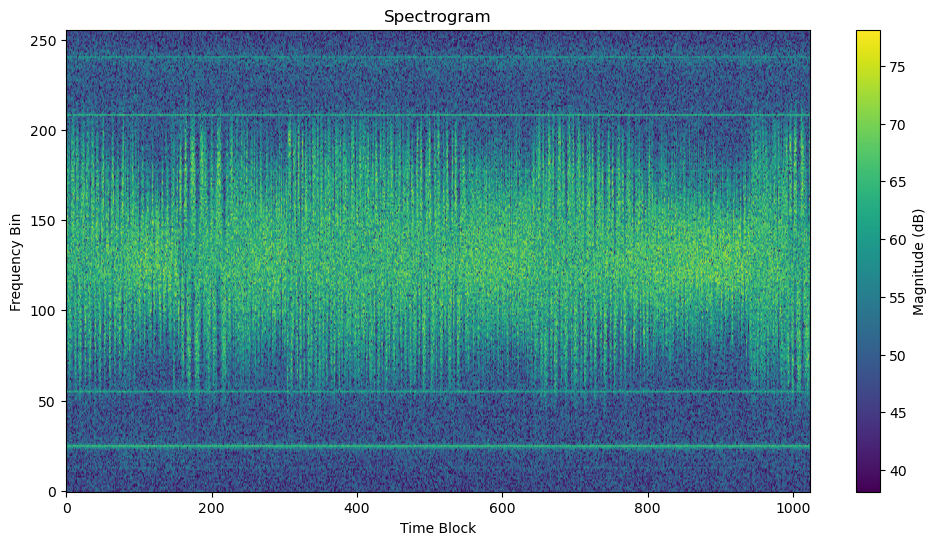

In [9]:
from scipy.signal import decimate
from msg import msg 
import matplotlib.pyplot as plt 

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\wfm_wqnr_10sec.bin")

samples = load_file(file_path)

# Initial decimate 

# Reduce the IQ sample rate by 8 
dfm_iq = decimate(samples, 8, ftype="fir") 
fs_dfm = fs / 8 # 256,000 samples/sec 


print("Decimated IQ samples:", len(dfm_iq)) 
print("Decimated sample rate:", fs_dfm, "samples/sec") 
print("Duration:", len(dfm_iq) / fs_dfm, "seconds")


### SPECTROGRAM ###

ds = msg(dfm_iq, 1, 256, 1024)




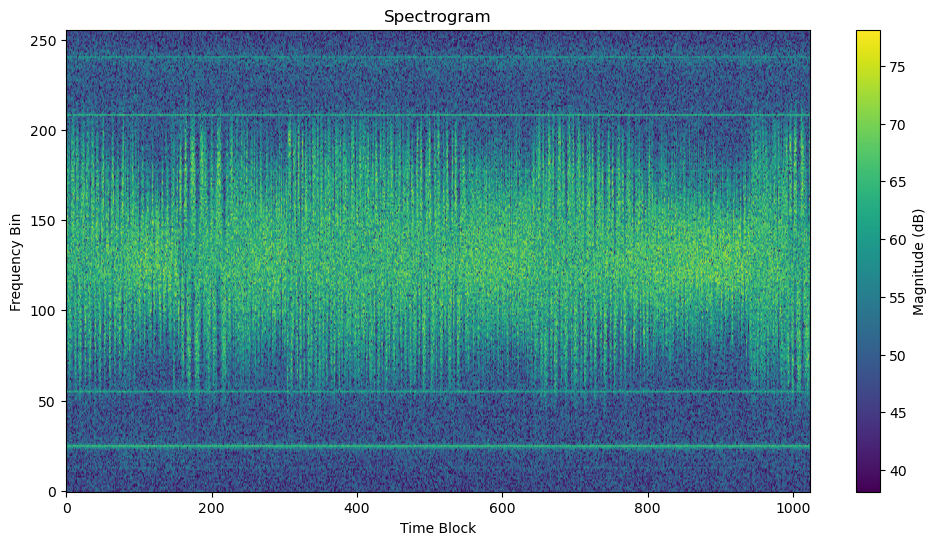

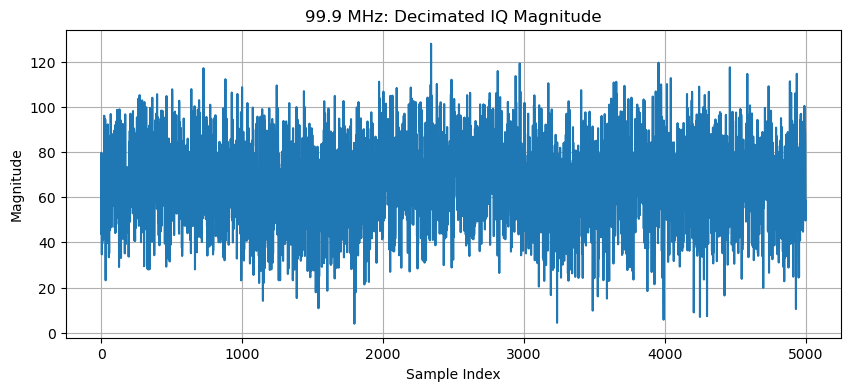

In [5]:
import matplotlib.pyplot as plt 


### MAGNATIUDE OF DECIMATED IQ  ###

plt.figure(figsize=(10, 4))

plt.plot(np.abs(dfm_iq[:5000]))

plt.xlabel("Sample Index")
plt.ylabel("Magnitude")
plt.title("99.9 MHz: Decimated IQ Magnitude")

plt.grid()
plt.show()

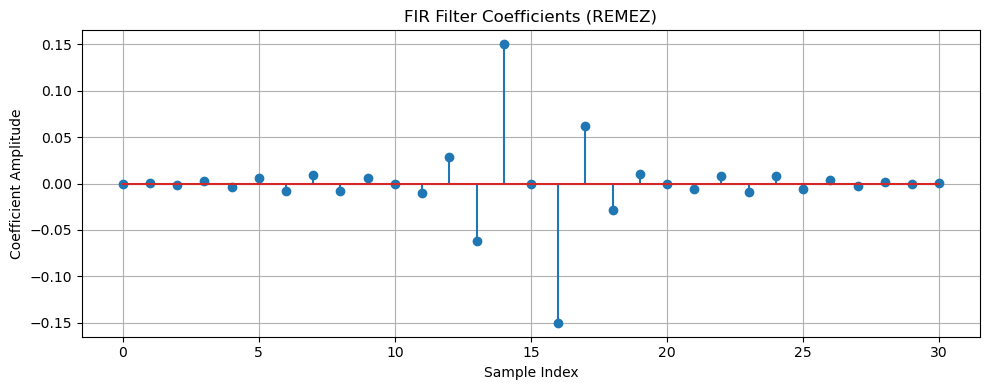

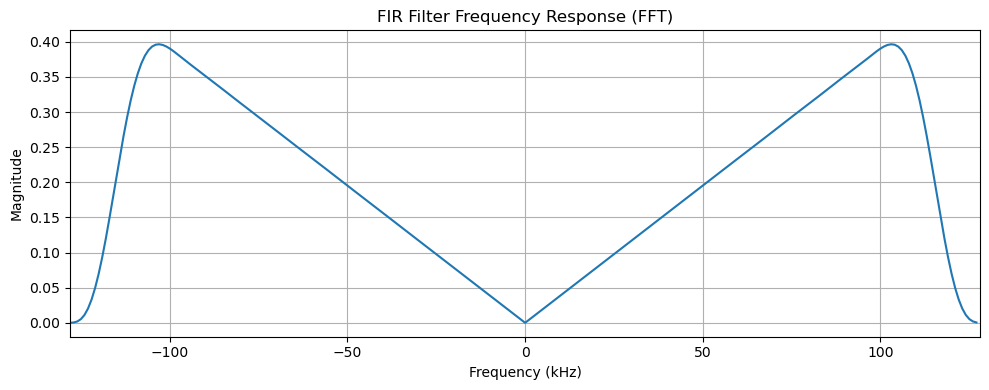

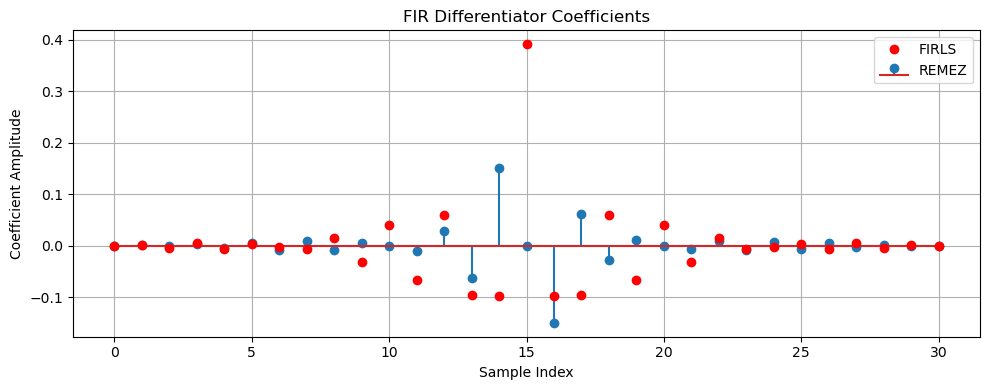

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# FM demodulation
audio_fm = np.angle(
    np.conj(dfm_iq[:-1]) * dfm_iq[1:]
)

# Filter specifications
fs = 256_000
numtaps = 31

# Design the 31-tap differentiator using REMEZ
hd = signal.remez(
    numtaps,
    [0, 100_000, 127_000, 128_000],
    [1, 0],
    type='differentiator',
    fs=fs
)

# Design the filter using FIRLS for comparison
hd_firls = signal.firls(
    numtaps,
    [0, 100_000, 127_000, 128_000],
    [0, 100_000 / (fs / 2), 0, 0],
    fs=fs
)

# Plot the REMEZ filter coefficients
plt.figure(figsize=(10, 4))
plt.stem(np.arange(len(hd)), hd)
plt.title("FIR Filter Coefficients (REMEZ)")
plt.xlabel("Sample Index")
plt.ylabel("Coefficient Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

# Compute the FFT of the REMEZ filter coefficients
N = 256
H = np.fft.fft(hd, n=N)

# Shift zero frequency to the center
H_shifted = np.fft.fftshift(H)

# Create the frequency axis in kHz
frequencies = np.fft.fftfreq(N, d=1 / fs)
frequencies_shifted = np.fft.fftshift(frequencies) / 1000

# Plot the centered magnitude spectrum
plt.figure(figsize=(10, 4))
plt.plot(frequencies_shifted, np.abs(H_shifted))
plt.title("FIR Filter Frequency Response (FFT)")
plt.xlabel("Frequency (kHz)")
plt.ylabel("Magnitude")
plt.xlim(-128, 128)
plt.grid(True)
plt.tight_layout()
plt.show()

# Compare the REMEZ and FIRLS coefficients
plt.figure(figsize=(10, 4))
plt.stem(np.arange(numtaps), hd, label="REMEZ")
plt.plot(np.arange(numtaps), hd_firls, "ro",
         label="FIRLS")
plt.title("FIR Differentiator Coefficients")
plt.xlabel("Sample Index")
plt.ylabel("Coefficient Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Input samples: 2560000
Output samples: 2560000


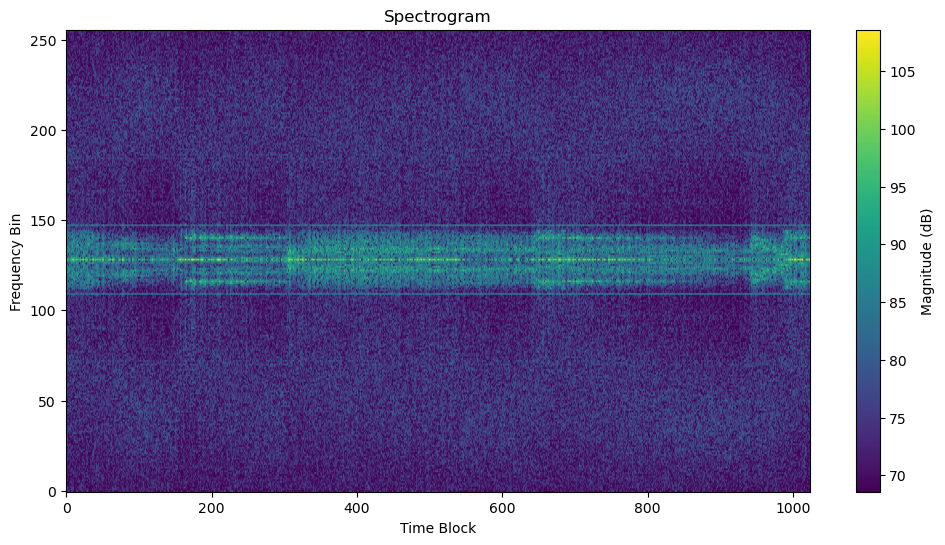

In [14]:

# Apply the FIR differentiator
filtered_fm = signal.convolve(dfm_iq, hd, mode="same")

# Extract the FM signal
df = np.imag(filtered_fm * np.conj(dfm_iq))

print("Input samples:", len(dfm_iq))
print("Output samples:", len(df))

output = msg(df, 1, 256, 1024)


In [18]:
from scipy.signal import decimate
from IPython.display import Audio, display
import numpy as np

# First decimation: 2.048 MHz / 8 = 256 kHz
dfd = decimate(df, 8, ftype='fir')

# Second decimation: 256 kHz / 8 = 128 kHz
dfd = decimate(dfd, 8, ftype='fir')

# Third decimation: 128 kHz / 8 = 16 kHz
dfd = decimate(dfd, 8, ftype='fir')

# Normalize the audio
dfd = dfd / np.max(np.abs(dfd))

# Plays audio
display(Audio(dfd, rate=16000))


Demodulated samples: 2559999
Approximate demodulated sample rate: 256000.0


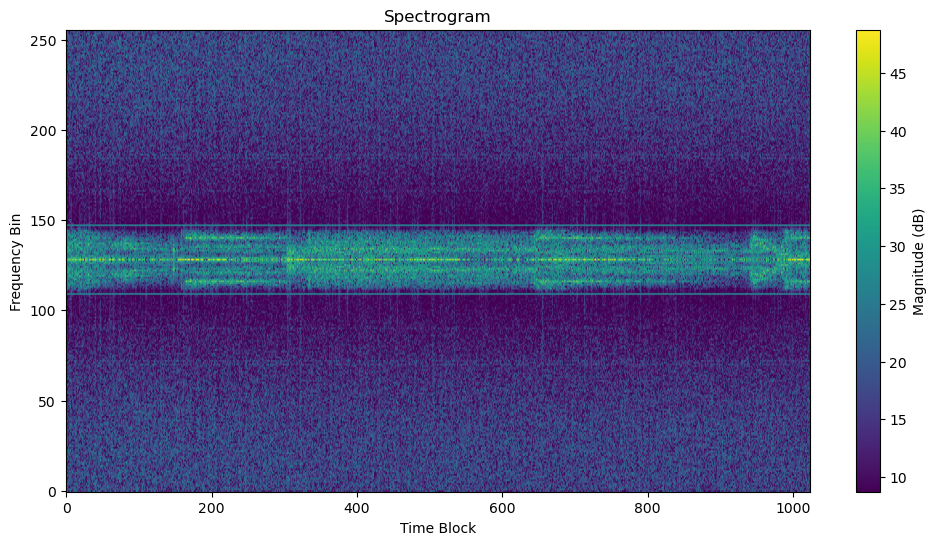

Audio playback sample rate: 42666.666666666664


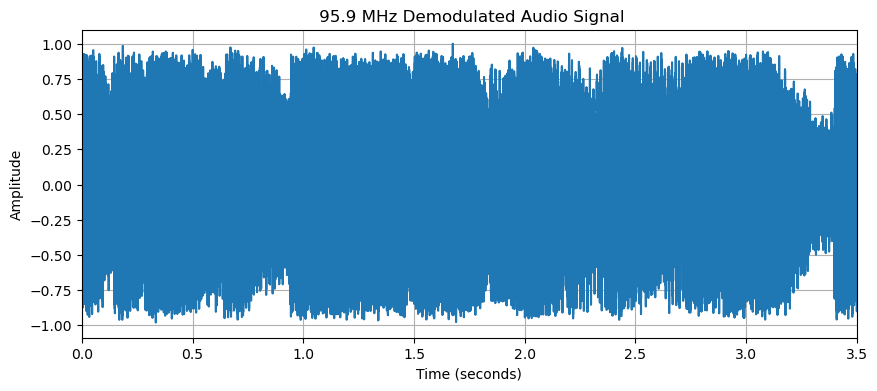

In [6]:
from IPython.display import Audio, display 
from msg import msg

# BASIC FM DEMODULATION 

audio_fm = np.angle(
    np.conj(dfm_iq[:-1]) * dfm_iq[1:]
)


# Remove DC offset
audio_fm = audio_fm - np.mean(audio_fm)

print("Demodulated samples:", len(audio_fm)) 
print("Approximate demodulated sample rate:", fs_dfm)

# Demodulated Signal Spectrogram 

ds_audio = msg(audio_fm, 1, 256, 1024)


# Prepare audio for Playback 
audio_out = decimate(audio_fm, 6, ftype="fir")
fs_audio = fs_dfm / 6


peak = np.max(np.abs(audio_out))

if peak > 0: 
    audio_out = audio_out / peak

print("Audio playback sample rate:", fs_audio)

#Plays audio 
display(Audio(audio_out, rate=int(fs_audio)))

#Display final plot 
t_audio = np.arange(len(audio_out)) / fs_audio

plt.figure(figsize=(10, 4))
plt.plot(t_audio, audio_out)

# since recording is 10 secs long - display only the first 3.5secs to examone the waveform more closely 
plt.xlim(0, min(3.5, len(audio_out) / fs_audio))
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title(" 95.9 MHz Demodulated Audio Signal")
plt.grid()

plt.show()